In [55]:
import pandas as pd
import seaborn as sns
import seaborn.objects as so
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

from matplotlib.cm import ScalarMappable

In [56]:
s2 = pd.read_csv("data/TableS2.csv", sep=";")

In [57]:
sample_correspondence = pd.read_csv("data/20241108Overview_KiTZ_samples_ribo_SMART-CARE_IDs.csv", sep=";")
sample_correspondence = sample_correspondence.merge(s2, left_on="v.Heesch ID", right_on="Sample_number", how="left")

In [58]:
sample_correspondence['SMART-CARE ID'] = sample_correspondence['SMART-CARE ID'].str.replace("SC_P_","")
sample_correspondence['SMART-CARE ID'] = sample_correspondence['SMART-CARE ID'].str.replace("A0", "A")
samples_tokeep = sample_correspondence[sample_correspondence['Ribo-seq']=='Yes']['SMART-CARE ID'].tolist()

In [59]:
sns.set(font="Arial")

In [60]:
ff = pd.read_csv('data/DKFZ/20251024_ORFs_DIANN_FF_Summary.csv')
ff

,Protein.Group,Protein.Names,Genes,First.Protein.Description,N.Sequences,N.Proteotypic.Sequences,A089,A089.1,A090,A092,...,A157,A158,A159,A160,A161,A165,A167,A168,A169,A170
0,ENSG00000000460__ENST00000359326__Trunc__0__AT...,PE=2,PE=2,NaN,8,0,NaN,NaN,418.300,360.588,...,361.682,NaN,593.690,NaN,NaN,607.854,NaN,635.305,792.868,NaN
1,ENSG00000001167__ENST00000341376__Trunc__0__AT...,PE=2,PE=2,NaN,4,2,2736.40,4376.15,6599.260,8198.750,...,6156.060,13420.600,7090.330,3286.57,6098.39,3314.390,NaN,4960.970,2274.570,8434.91
2,ENSG00000008056_ENSG00000126759__ENST000002959...,PE=2,PE=2,NaN,30,0,NaN,NaN,46492.000,1513.740,...,1206.480,29489.300,14507.500,6136.70,2287.09,32974.700,NaN,NaN,8716.750,NaN
3,ENSG00000011105__ENST00000011898__Variant__0__...,PE=2,PE=2,NaN,3,0,10425.70,6613.58,3628.310,3323.720,...,3419.230,1289.600,4001.990,3611.84,6094.28,13885.000,5193.62,1644.490,1339.300,19096.50
4,ENSG00000019485__TCONS_00127435__ncRNA__2__AGG...,PE=2,PE=2,NaN,1,1,NaN,NaN,186.244,215.092,...,205.908,NaN,168.497,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
529,TCONS_00843332_10336_11028_NEOTRANSCRIPT,PE=2,PE=2,NaN,5,1,259878.00,364276.00,307931.000,237677.000,...,256025.000,184210.000,156854.000,120903.00,93872.30,310390.000,1600000.00,88062.600,38133.900,329298.00
530,TCONS_00844010_193_2010_NEOTRANSCRIPT,PE=2,PE=2,NaN,22,1,5439.00,5355.47,9712.750,14431.100,...,3552.200,13464.000,14049.300,23208.80,14408.50,15746.200,8788.55,3686.920,6813.660,10194.00
531,TCONS_00846234_123_3137_NEOTRANSCRIPT,PE=2,PE=2,NaN,1,0,NaN,NaN,1916.530,1635.540,...,NaN,767.383,850.094,NaN,NaN,3487.050,NaN,NaN,NaN,NaN
532,TCONS_00881198_562_4443_NEOTRANSCRIPT,PE=2,PE=2,NaN,32,1,3460.26,3426.77,3537.620,4634.270,...,3439.820,2387.520,4169.200,6933.82,3621.91,3721.470,NaN,3742.650,4306.520,NaN


In [61]:
new_cols = ['Protein.Group', 'Protein.Names', 'Genes', 'First.Protein.Description',
       'N.Sequences', 'N.Proteotypic.Sequences'] + samples_tokeep

In [62]:
ff = ff[new_cols]

In [63]:
meta = pd.read_csv('data/meta/20260219_EwS_ncORF_metadata_summary.tsv', sep='\t')
meta

,orf_id,ORF_ranges,Protein,gene_id,gene_biotype,gene_name,transcript_id,uniprot_gn_ids,cl_mean,ps_mean,...,Number_SB,Peptides_WB,Number_WB,class,any_peptide_found_in_IP,result_A673,result_SKNMC,result_MHHES,result_TC106,result_RDES
0,ENSG00000159167__ENST00000290271__uORF__2__GTG,8:23854633-23854746,MAAAAAAAAAAAAAEAPVAAAASPATTTKKNPHQILT,ENSG00000159167,protein_coding,STC1,ENST00000290271,A0A0H3W641;P52823,1.187192,2.508946,...,NaN,NaN,NaN,0.0,False,not expressed,not expressed,upregulated,ns,ns
1,ENST00000291041_23_121,16:67893276-67908682,MAAAAAAAAAAAIARRWPAEPPRRRRARRPREV,ENSG00000159792,protein_coding,PSKH1,ENST00000291041,P11801;A0A087WZT9,23.079040,17.597305,...,NaN,NaN,NaN,1.0,True,ns,ns,ns,ns,ns
2,ENST00000216727_182_1099,14:23321470-23325283,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...,ENSG00000100836,protein_coding,PABPN1,ENST00000216727,B4DEH8;Q86U42;G3V4T2,72.570950,51.634440,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ENST00000397276_14_901,14:23321470-23324296,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...,ENSG00000100836,protein_coding,PABPN1,ENST00000397276,B4DEH8;Q86U42;G3V4T2,71.136807,50.211111,...,NaN,NaN,NaN,NaN,NaN,ns,ns,ns,ns,ns
4,ENST00000354300_17_85,12:110583234-110583302,MAAAAAAAAAGTSVGLRRRSRRF,ENSG00000196850,protein_coding,PPTC7,ENST00000354300,Q8NI37,14.741234,14.913901,...,NaN,NaN,NaN,0.0,False,not expressed,ns,upregulated,ns,ns
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62178,ENSG00000116604__TCONS_00065632__ncRNA__9__ATT,1:156483398-156500599,MYYSPRPELRLPGVEDPPDQGRGLPALCRDNTVPPAGLEAVQKVSCRP,ENSG00000116604,protein_coding,MEF2D,TCONS_00065632,Q14814;Q05BX2,12.438524,33.178861,...,NaN,NaN,NaN,0.0,False,ns,ns,ns,ns,ns
62179,ENST00000552151_8_454,12:70310970-70330470,MYYSQSSMFPHRSEKDMLASPSTSGQLSQFGASLYGQQSALGLPMR...,ENSG00000111596,protein_coding,CNOT2,ENST00000552151,F8VSK9;Q9NZN8;F8VUB4;F8W145;F8VPX5;F8VVY1;F8VV...,12.182117,23.360930,...,NaN,NaN,NaN,NaN,NaN,ns,ns,ns,ns,ns
62180,ENST00000495930_268_459,13:112875798-112875989,MYYVFIQMLSSGPAWLAIVLLVTISLLPDVLKKVLCRQLWPTATER...,ENSG00000068650,protein_coding,ATP11A,ENST00000495930,P98196;E9PEJ6;A2A3G9;A0A087WVE8,6.739418,19.103163,...,NaN,NaN,NaN,NaN,NaN,not expressed,ns,ns,ns,ns
62181,ENSG00000181392_ENSG00000239382__ENST000004904...,19:36010923-36013077,MYYVPDFISKEEEEYLLRQVFNAPKPKWTQLSGRKLQNWGPHCLPQ...,ENSG00000239382,protein_coding,ALKBH6,ENST00000490483,Q3KRA9;E9PI76;S4R3C7;H0YD83,10.796175,7.697037,...,NaN,NaN,NaN,NaN,NaN,ns,ns,ns,ns,ns


In [64]:
ff['Protein.Group'] = ff['Protein.Group'].apply(lambda x: x.split(';'))
ff = ff.explode('Protein.Group')
ff.rename(columns={'Protein.Group': 'Protein'}, inplace=True)
ff['Protein'] = ff['Protein'].str.replace('_NEOTRANSCRIPT', '', regex=False)
ff

C:\Users\Masha\AppData\Local\Temp\ipykernel_1612\2827165496.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ff['Protein.Group'] = ff['Protein.Group'].apply(lambda x: x.split(';'))


,Protein,Protein.Names,Genes,First.Protein.Description,N.Sequences,N.Proteotypic.Sequences,A089,A090,A092,A094,...,A144,A145,A147,A149,A151,A152,A165,A167,A168,A170
0,ENSG00000000460__ENST00000359326__Trunc__0__ATG,PE=2,PE=2,NaN,8,0,NaN,418.300,360.588,422.051,...,341.799,760.338,429.43,NaN,428.909,1052.29,607.854,NaN,635.305,NaN
1,ENSG00000001167__ENST00000341376__Trunc__0__ATG,PE=2,PE=2,NaN,4,2,2736.40,6599.260,8198.750,10098.200,...,5897.920,5132.920,6082.94,9675.81,6501.840,5440.54,3314.390,NaN,4960.970,8434.91
2,ENSG00000008056_ENSG00000126759__ENST000002959...,PE=2,PE=2,NaN,30,0,NaN,46492.000,1513.740,21479.000,...,5361.910,15941.700,149764.00,12901.80,NaN,4903.02,32974.700,NaN,NaN,NaN
3,ENSG00000011105__ENST00000011898__Variant__0__GTG,PE=2,PE=2,NaN,3,0,10425.70,3628.310,3323.720,3532.690,...,3494.460,2097.240,1338.03,1254.30,1175.130,1359.25,13885.000,5193.62,1644.490,19096.50
4,ENSG00000019485__TCONS_00127435__ncRNA__2__AGG,PE=2,PE=2,NaN,1,1,NaN,186.244,215.092,396.582,...,NaN,360.812,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
529,TCONS_00843332_10336_11028,PE=2,PE=2,NaN,5,1,259878.00,307931.000,237677.000,316670.000,...,220288.000,262495.000,177822.00,274153.00,292539.000,299315.00,310390.000,1600000.00,88062.600,329298.00
530,TCONS_00844010_193_2010,PE=2,PE=2,NaN,22,1,5439.00,9712.750,14431.100,15428.900,...,21962.500,11674.400,6587.52,11763.70,12833.400,33123.20,15746.200,8788.55,3686.920,10194.00
531,TCONS_00846234_123_3137,PE=2,PE=2,NaN,1,0,NaN,1916.530,1635.540,2304.800,...,1069.160,1106.520,1450.94,5506.67,504.740,NaN,3487.050,NaN,NaN,NaN
532,TCONS_00881198_562_4443,PE=2,PE=2,NaN,32,1,3460.26,3537.620,4634.270,3466.460,...,4041.060,2971.810,3638.08,3111.71,3240.810,3408.88,3721.470,NaN,3742.650,NaN


In [65]:
merge_ff = ff.merge(meta, left_on='Protein', right_on='orf_id', how='left')
merge_ff

,Protein_x,Protein.Names,Genes,First.Protein.Description,N.Sequences,N.Proteotypic.Sequences,A089,A090,A092,A094,...,Number_SB,Peptides_WB,Number_WB,class,any_peptide_found_in_IP,result_A673,result_SKNMC,result_MHHES,result_TC106,result_RDES
0,ENSG00000000460__ENST00000359326__Trunc__0__ATG,PE=2,PE=2,NaN,8,0,NaN,418.300,360.588,422.051,...,NaN,NaN,NaN,NaN,NaN,ns,ns,ns,ns,ns
1,ENSG00000001167__ENST00000341376__Trunc__0__ATG,PE=2,PE=2,NaN,4,2,2736.40,6599.260,8198.750,10098.200,...,NaN,NaN,NaN,NaN,NaN,ns,ns,ns,ns,ns
2,ENSG00000008056_ENSG00000126759__ENST000002959...,PE=2,PE=2,NaN,30,0,NaN,46492.000,1513.740,21479.000,...,NaN,NaN,NaN,NaN,NaN,ns,downregulated,upregulated,ns,ns
3,ENSG00000011105__ENST00000011898__Variant__0__GTG,PE=2,PE=2,NaN,3,0,10425.70,3628.310,3323.720,3532.690,...,NaN,NaN,NaN,NaN,NaN,ns,ns,upregulated,ns,upregulated
4,ENSG00000019485__TCONS_00127435__ncRNA__2__AGG,PE=2,PE=2,NaN,1,1,NaN,186.244,215.092,396.582,...,NaN,NaN,NaN,NaN,NaN,ns,upregulated,ns,ns,ns
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
577,TCONS_00843332_10336_11028,PE=2,PE=2,NaN,5,1,259878.00,307931.000,237677.000,316670.000,...,NaN,NaN,NaN,0.0,False,ns,ns,ns,ns,ns
578,TCONS_00844010_193_2010,PE=2,PE=2,NaN,22,1,5439.00,9712.750,14431.100,15428.900,...,NaN,NaN,NaN,NaN,NaN,ns,ns,downregulated,ns,ns
579,TCONS_00846234_123_3137,PE=2,PE=2,NaN,1,0,NaN,1916.530,1635.540,2304.800,...,NaN,NaN,NaN,NaN,NaN,ns,ns,upregulated,upregulated,ns
580,TCONS_00881198_562_4443,PE=2,PE=2,NaN,32,1,3460.26,3537.620,4634.270,3466.460,...,NaN,NaN,NaN,NaN,NaN,ns,ns,ns,ns,ns


In [66]:
merge_ff[merge_ff['neotranscript_orf_type']=='Neogene ORF']

,Protein_x,Protein.Names,Genes,First.Protein.Description,N.Sequences,N.Proteotypic.Sequences,A089,A090,A092,A094,...,Number_SB,Peptides_WB,Number_WB,class,any_peptide_found_in_IP,result_A673,result_SKNMC,result_MHHES,result_TC106,result_RDES
481,Ew_NG3.4_97_360,PE=2,PE=2,NaN,1,1,NaN,404.934,NaN,NaN,...,13.0,"NEDPYLHCSSI,KPFKGKGKTAS,GKTASSHSSEK,KTASSHSSEK...",45.0,1.0,True,ns,upregulated,ns,ns,upregulated
575,TCONS_00842344_338_622,PE=2,PE=2,NaN,1,1,NaN,NaN,NaN,NaN,...,11.0,"ARALGLLASGR,SRALPAPEEAW,DHQAANQRPAV,AANQRPAVEE...",33.0,0.0,False,not expressed,downregulated,downregulated,upregulated,ns


In [67]:
ff_samples = samples_tokeep


In [68]:
merge_ff['Length'] = merge_ff['Protein_y'].apply(len)

In [69]:
def normalize(df, intensity_cols):
    df_norm = df.copy()
    # Compute median ignoring zeros and NAs
    sample_medians = {}
    for col in intensity_cols:
        non_zero = df[col].replace(0, np.nan).dropna()
        sample_medians[col] = non_zero.median() if len(non_zero) > 0 else 1
    
    global_median = np.median(list(sample_medians.values()))
    
    for col in intensity_cols:
        df_norm[col] = df[col] / sample_medians[col] * global_median
    return df_norm

In [70]:
merge_ff.fillna(0, inplace=True)

In [71]:
ff_n = normalize(merge_ff, ff_samples)

In [72]:
ff_n['A167']

0           0.000000
1           0.000000
2           0.000000
3         967.317196
4           0.000000
           ...      
577    298001.685452
578      1636.876695
579         0.000000
580         0.000000
581      2222.273069
Name: A167, Length: 582, dtype: float64

In [73]:
ff_n['orf_category_new'].value_counts()

orf_category_new
ORF_variant             550
pseudogene ORF           14
uORF                      8
uoORF                     4
dORF                      3
neogene ORF               2
unannotated gene ORF      1
Name: count, dtype: int64

In [74]:
ff_n['neotranscript_orf_type'].value_counts()

neotranscript_orf_type
ORF_variant                  547
Non-canonical ORF general     30
In-frame ORF                   3
Neogene ORF                    2
Name: count, dtype: int64

In [75]:
ff_n['orf_cathegoty_toplot'] = ff_n['neotranscript_orf_type'].where(ff_n['neotranscript_orf_type'] != 'Non-canonical ORF general', ff_n['orf_category_new'])

In [76]:
ff_n['orf_cathegoty_toplot'].value_counts()

orf_cathegoty_toplot
ORF_variant             547
pseudogene ORF           14
uORF                      8
uoORF                     4
dORF                      3
In-frame ORF              3
Neogene ORF               2
unannotated gene ORF      1
Name: count, dtype: int64

In [77]:
palette = {
    "Neogene ORF": "#1b365d",
    "In-frame ORF": "#6ea9d2",
    "ORF_variant": "#FFB347",
    "Canonical_protein": "#77DD77",
    "lncRNA ORF": "#D32F2F",
    "dORF": "#32936F",
    "doORF": "#80baa5",
    "intORF": "#d9d9d9",
    "uORF": "#6c57b7",
    "uoORF": "#a091d4",
    "pseudogene ORF": "#F15BB5",
    "unannotated gene ORF": "#e0c219"
}

In [78]:
ff_n = ff_n[ff_n['orf_cathegoty_toplot']!='ORF_variant']

In [79]:
ff_n.rename(columns={'Protein_x': 'Protein'}, inplace=True)

In [80]:
ncORFs_detected_DKFZ =  set(ff_n[ff_n['gene_name'] != 'H2BP2']['Protein'].tolist())
len(ncORFs_detected_DKFZ)

34

In [81]:
ff_cols = ['gene_name', 'orf_cathegoty_toplot'] + ff_samples

In [82]:
ff_n_nc = ff_n[ff_cols]

In [83]:
ff_n_nc = ff_n_nc[ff_n_nc['gene_name'] != 'H2BP2']
ff_n_nc = ff_n_nc[ff_n_nc['gene_name'] != 'APBA2']


In [84]:
from pandas.api.types import CategoricalDtype

In [85]:
MY_ORDER = ['Neogene ORF', 'In-frame ORF', 'lncRNA ORF', 'dORF', 'doORF', 'intORF', 'uORF', 'uoORF', 'pseudogene ORF', 'unannotated gene ORF']
MY_CAT_ORDER = CategoricalDtype(MY_ORDER, ordered=True)

ff_n_nc['orf_cathegoty_toplot'] = ff_n_nc['orf_cathegoty_toplot'].astype(MY_CAT_ORDER)
ff_n_nc = ff_n_nc.sort_values('orf_cathegoty_toplot')

In [86]:
glue = ff_n_nc.set_index('gene_name').drop(columns=['orf_cathegoty_toplot'])
row_colors = ff_n_nc.set_index('gene_name')['orf_cathegoty_toplot'].map(palette)

In [87]:
def log2_median_normalize(df):
    """Log2-transform and median-center each column. Preserves NaN."""
    log_vals = np.log2(df)  # NaN stays NaN
    medians = log_vals.median()  # automatically skips NaN
    return log_vals - medians

In [88]:
#glue = log2_median_normalize(glue)
glue_nonzero = glue.replace(0, np.nan)
glue_normalized = log2_median_normalize(glue_nonzero)

In [89]:
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42   # <-- ADD THIS before creating the figure
matplotlib.rcParams['ps.fonttype'] = 42  

In [90]:
import matplotlib as mpl
import matplotlib.colors as mcolors


plasma_darkest_hex = mcolors.to_hex(mpl.cm.plasma(0.0))

cmap = mpl.cm.RdBu_r.copy()
cmap.set_bad(plasma_darkest_hex)

In [91]:
print(mcolors.to_hex(mpl.cm.plasma(0.0))) 

#0d0887


In [92]:
import matplotlib.patches as mpatches

row_patches = [
    mpatches.Patch(color=color, label=label)
    for label, color in palette.items()
]

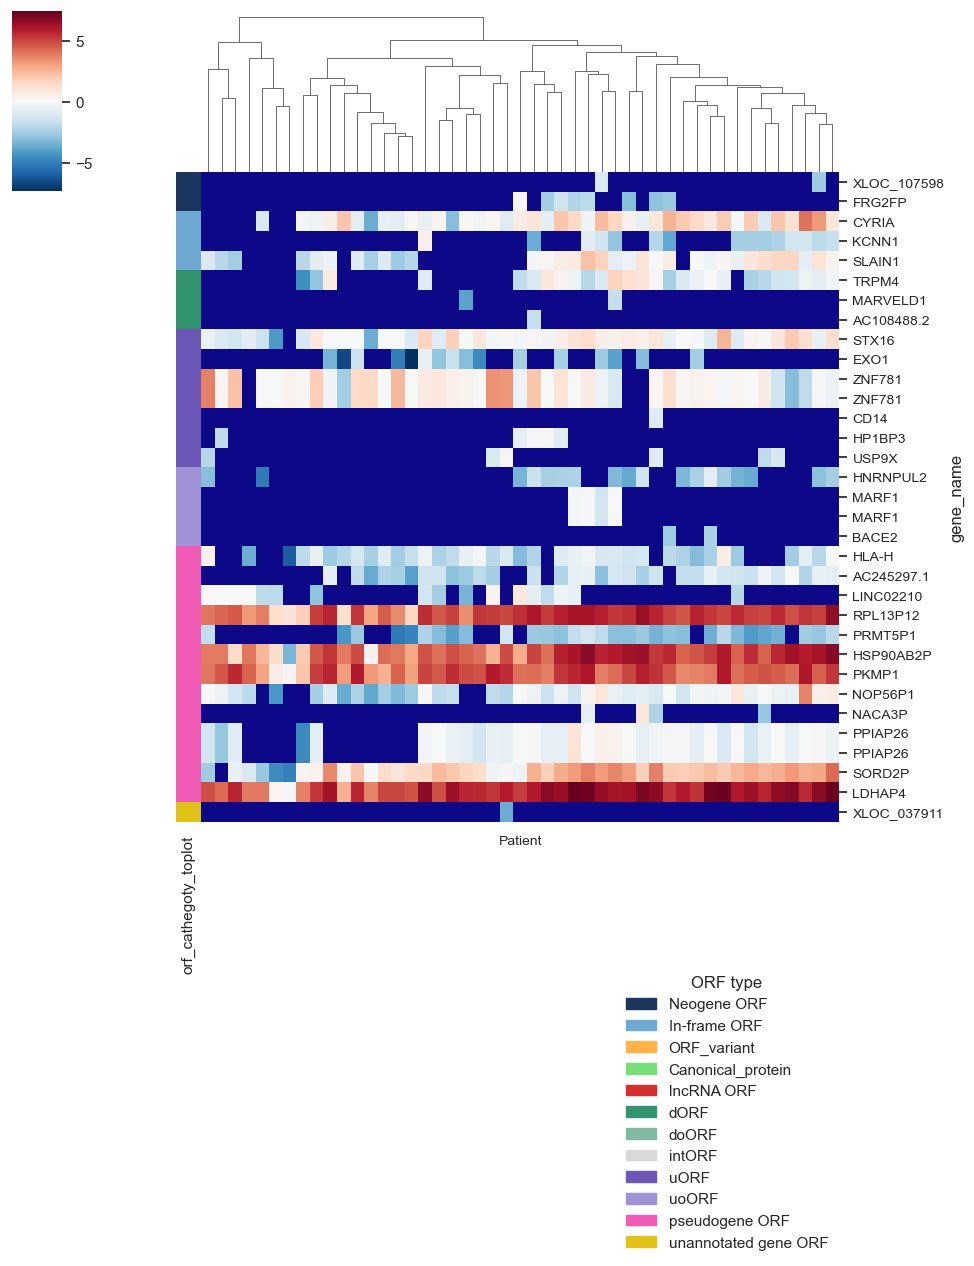

In [93]:
g = sns.clustermap(
    glue_normalized.fillna(glue_normalized.min().min() - 1),  # fill for clustering
    mask=glue_normalized.isna(),  # mask the original NaN positions
    cmap=cmap,
    xticklabels=False,
    yticklabels=True,
    figsize=(10, 10),
    col_cluster=True,
    row_cluster=False,
    annot=False,
    row_colors=row_colors
)

# Adjust font sizes
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), fontsize=10)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), fontsize=10)
g.ax_heatmap.set_xlabel("Patient", fontsize=10, labelpad=10)

leg2 = g.cax.legend(
    handles=row_patches,
    title="ORF type",
    loc="upper right",
    bbox_to_anchor=(0.85, 0.03), 
    bbox_transform=g.figure.transFigure,
    frameon=False
)

for text in g.ax_heatmap.texts:
    text.set_fontsize(8)

g.ax_heatmap.tick_params(axis='x', rotation=90)

plt.savefig('DKFZ_FF_proteomics_ncORF_clustermap_16022026.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [94]:
ff_n_nc['orf_cathegoty_toplot'].value_counts()

orf_cathegoty_toplot
pseudogene ORF          13
uORF                     7
uoORF                    4
In-frame ORF             3
dORF                     3
Neogene ORF              2
unannotated gene ORF     1
lncRNA ORF               0
doORF                    0
intORF                   0
Name: count, dtype: int64

In [95]:
meta_d = pd.read_csv("meta_with_detection.csv")
meta_d

,orf_id,ORF_ranges,Protein,gene_id,gene_biotype,gene_name,transcript_id,uniprot_gn_ids,cl_mean,ps_mean,...,detected_MSK,detected_tr,detected_DKFZ,orf_cathegoty_toplot,detected_1,detected_1_in_at_least_2_samples,detected_2,detected_2_in_at_least_2_samples,detected_3,detected_3_in_at_least_2_samples
0,ENSG00000159167__ENST00000290271__uORF__2__GTG,8:23854633-23854746,MAAAAAAAAAAAAAEAPVAAAASPATTTKKNPHQILT,ENSG00000159167,protein_coding,STC1,ENST00000290271,A0A0H3W641;P52823,1.187192,2.508946,...,False,False,False,uORF,False,False,False,False,False,False
1,ENST00000291041_23_121,16:67893276-67908682,MAAAAAAAAAAAIARRWPAEPPRRRRARRPREV,ENSG00000159792,protein_coding,PSKH1,ENST00000291041,P11801;A0A087WZT9,23.079040,17.597305,...,False,False,False,uORF,False,False,False,False,False,False
2,ENST00000216727_182_1099,14:23321470-23325283,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...,ENSG00000100836,protein_coding,PABPN1,ENST00000216727,B4DEH8;Q86U42;G3V4T2,72.570950,51.634440,...,False,False,False,ORF_annotated,False,False,False,False,False,False
3,ENST00000397276_14_901,14:23321470-23324296,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...,ENSG00000100836,protein_coding,PABPN1,ENST00000397276,B4DEH8;Q86U42;G3V4T2,71.136807,50.211111,...,False,False,False,ORF_variant,False,False,False,False,False,False
4,ENST00000354300_17_85,12:110583234-110583302,MAAAAAAAAAGTSVGLRRRSRRF,ENSG00000196850,protein_coding,PPTC7,ENST00000354300,Q8NI37,14.741234,14.913901,...,False,False,False,uORF,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62178,ENSG00000116604__TCONS_00065632__ncRNA__9__ATT,1:156483398-156500599,MYYSPRPELRLPGVEDPPDQGRGLPALCRDNTVPPAGLEAVQKVSCRP,ENSG00000116604,protein_coding,MEF2D,TCONS_00065632,Q14814;Q05BX2,12.438524,33.178861,...,False,False,False,uORF,False,False,False,False,False,False
62179,ENST00000552151_8_454,12:70310970-70330470,MYYSQSSMFPHRSEKDMLASPSTSGQLSQFGASLYGQQSALGLPMR...,ENSG00000111596,protein_coding,CNOT2,ENST00000552151,F8VSK9;Q9NZN8;F8VUB4;F8W145;F8VPX5;F8VVY1;F8VV...,12.182117,23.360930,...,False,False,False,ORF_variant,False,False,False,False,False,False
62180,ENST00000495930_268_459,13:112875798-112875989,MYYVFIQMLSSGPAWLAIVLLVTISLLPDVLKKVLCRQLWPTATER...,ENSG00000068650,protein_coding,ATP11A,ENST00000495930,P98196;E9PEJ6;A2A3G9;A0A087WVE8,6.739418,19.103163,...,False,False,False,ORF_variant,False,False,False,False,False,False
62181,ENSG00000181392_ENSG00000239382__ENST000004904...,19:36010923-36013077,MYYVPDFISKEEEEYLLRQVFNAPKPKWTQLSGRKLQNWGPHCLPQ...,ENSG00000239382,protein_coding,ALKBH6,ENST00000490483,Q3KRA9;E9PI76;S4R3C7;H0YD83,10.796175,7.697037,...,False,False,False,ORF_variant,False,False,False,False,False,False


In [96]:
ff_n = ff_n[ff_n['Protein']!='ENST00000609585_225_449']

In [97]:
col = ['Protein'] + ff_samples

In [98]:
nc = ff_n[col]
nc

,Protein,A089,A090,A092,A094,A097,A099,A101,A103,A104,...,A144,A145,A147,A149,A151,A152,A165,A167,A168,A170
7,ENSG00000034053__ENST00000558402__uORF__4__CTG,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
80,ENSG00000124222_ENSG00000215440__ENST000003711...,3951.026764,6901.322288,5764.130999,6048.166622,5031.937396,5721.377398,16715.428169,1980.744238,5425.187387,...,3749.514012,5350.617936,3945.296191,2965.087530,3607.651741,4872.137416,1087.992778,2216.164034,3123.126688,0.000000
81,ENSG00000124486__ENST00000324545__uORF__10__TTG,0.000000,2105.983494,1530.281211,1384.545673,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
87,ENSG00000127483__ENST00000487117__ncRNA__8__CTG,2480.374153,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1551.702763,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
93,ENSG00000130529_XLOC_050006__TCONS_00433586__n...,0.000000,4162.663774,1323.834028,1236.537654,0.000000,947.510828,1623.944134,1653.157442,504.973752,...,3284.721933,8325.684429,10179.385293,5084.327369,5112.789897,1906.098307,0.000000,0.000000,0.000000,0.000000
132,ENSG00000150276__TCONS_00221354__ncRNA__0__ATG,1229.960586,3147.411667,3980.126601,3325.173585,0.000000,1858.764480,2775.762678,2974.775409,2067.799634,...,1694.559706,3476.224781,3657.681310,0.000000,1641.152070,4943.723323,0.000000,3253.992154,0.000000,0.000000
133,TCONS_00229020_731_1222,1229.960586,3147.411667,3980.126601,3325.173585,0.000000,1858.764480,2775.762678,2974.775409,2067.799634,...,1694.559706,3476.224781,3657.681310,0.000000,1641.152070,4943.723323,0.000000,3253.992154,0.000000,0.000000
139,ENSG00000155254__ENST00000285605__dORF__2__ATG,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,906.850938,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
161,ENSG00000166783__ENST00000551742__uoORF__6__GTG,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1995.191846,...,0.000000,0.000000,2962.628265,0.000000,0.000000,2107.186634,0.000000,0.000000,0.000000,0.000000
162,ENST00000540441_17_85,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1995.191846,...,0.000000,0.000000,2962.628265,0.000000,0.000000,2107.186634,0.000000,0.000000,0.000000,0.000000


In [99]:
total_proteins = nc['Protein'].tolist()

In [100]:
meta_d['detected_3'] = meta_d['orf_id'].apply(lambda x: x in total_proteins)

In [101]:
nc_indexed = nc.set_index('Protein')

meta_d['detected_3_in_at_least_2_samples'] = meta_d['orf_id'].apply(
    lambda x: (nc_indexed[ff_samples].loc[x] > 0).sum() >= 2 
    if x in nc_indexed.index 
    else False
)

In [102]:
meta_d.to_csv('meta_with_detection.csv', index=False)

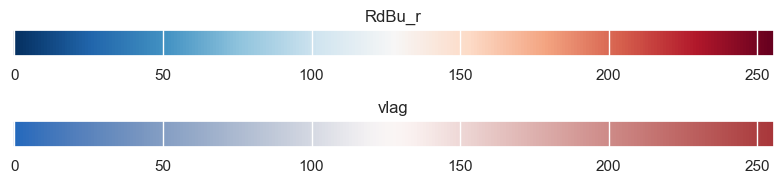

In [103]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, axes = plt.subplots(2, 1, figsize=(8, 2))
gradient = np.linspace(-1, 1, 256).reshape(1, -1)

axes[0].imshow(gradient, cmap="RdBu_r", aspect="auto")
axes[0].set_title("RdBu_r")
axes[0].set_yticks([])

axes[1].imshow(gradient, cmap="vlag", aspect="auto")
axes[1].set_title("vlag")
axes[1].set_yticks([])

plt.tight_layout()
plt.show()

In [104]:
nc.to_csv('DKFZ_FF_ncORF_proteomics_normalized.csv', index=False)

In [105]:
len(samples_tokeep)

47

In [106]:
ff_n_nc[ff_n_nc['gene_name']=='TRPM4'][samples_tokeep].astype(bool).sum(axis=1)

93    27
dtype: int64